# Mattioli Simone - Emotion Detection in Text

- **DATASET USED:** https://huggingface.co/datasets/dair-ai/emotion

## Imports

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis (EDA)

In [40]:
train_df = pd.read_csv("data/train.csv")
val_df = pd.read_csv("data/validation.csv")
test_df = pd.read_csv("data/test.csv")

print("Training data:", train_df.shape)
print("Validation data:", val_df.shape)
print("Testing data:", test_df.shape)

print()
print()

print(train_df.head())

print()
print()

Training data: (16000, 2)
Validation data: (2000, 2)
Testing data: (2000, 2)


                                                text  label
0                            i didnt feel humiliated      0
1  i can go from feeling so hopeless to so damned...      0
2   im grabbing a minute to post i feel greedy wrong      3
3  i am ever feeling nostalgic about the fireplac...      2
4                               i am feeling grouchy      3




### Emotion Labels presents

In [41]:
# From the DOCUMENTATION:
emotion_labels = {
    0: "sadness",
    1: "joy",
    2: "love",
    3: "anger",
    4: "fear",
    5: "surprise"
}

train_df["emotion"] = train_df["label"].map(emotion_labels)

train_df.head()

,text,label,emotion
0,i didnt feel humiliated,0,sadness
1,i can go from feeling so hopeless to so damned...,0,sadness
2,im grabbing a minute to post i feel greedy wrong,3,anger
3,i am ever feeling nostalgic about the fireplac...,2,love
4,i am feeling grouchy,3,anger


### Checking Actual Values

In [42]:
print("Missing values:")
print(train_df.isnull().sum())

print("\nDuplicate texts:")
print(train_df["text"].duplicated().sum())

print("\nEmpty texts:")
print(train_df["text"].str.strip().eq("").sum())


Missing values:
text       0
label      0
emotion    0
dtype: int64

Duplicate texts:
31

Empty texts:
0


### Distribution of the emotion

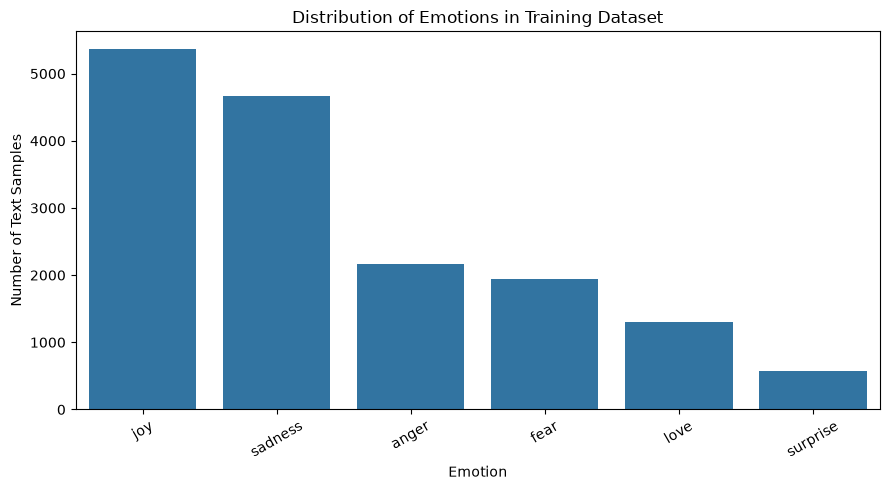

Emotion Counts:
emotion
joy         5362
sadness     4666
anger       2159
fear        1937
love        1304
surprise     572
Name: count, dtype: int64


Emotion percentages:
emotion
joy         33.51
sadness     29.16
anger       13.49
fear        12.11
love         8.15
surprise     3.58
Name: proportion, dtype: float64


In [43]:
emotion_counts = train_df["emotion"].value_counts()

# Calculate percentages
emotion_percentages = (
    train_df["emotion"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

plt.figure(figsize=(9, 5))

sns.countplot(
    data=train_df,
    x="emotion",
    order=train_df["emotion"].value_counts().index
)

plt.title("Distribution of Emotions in Training Dataset")
plt.xlabel("Emotion")
plt.ylabel("Number of Text Samples")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


print("Emotion Counts:")
print(emotion_counts)
print()

print("\nEmotion percentages:")
print(emotion_percentages)


### Text Lengths

In [47]:
train_df["word_count"] = (
    # How many words in each text?
    train_df["text"].str.split().str.len()
)

print(f"""Median: {train_df["word_count"].median()}""")
print(train_df["word_count"].describe())

Median: 17.0
count    16000.000000
mean        19.166313
std         10.986905
min          2.000000
25%         11.000000
50%         17.000000
75%         25.000000
max         66.000000
Name: word_count, dtype: float64


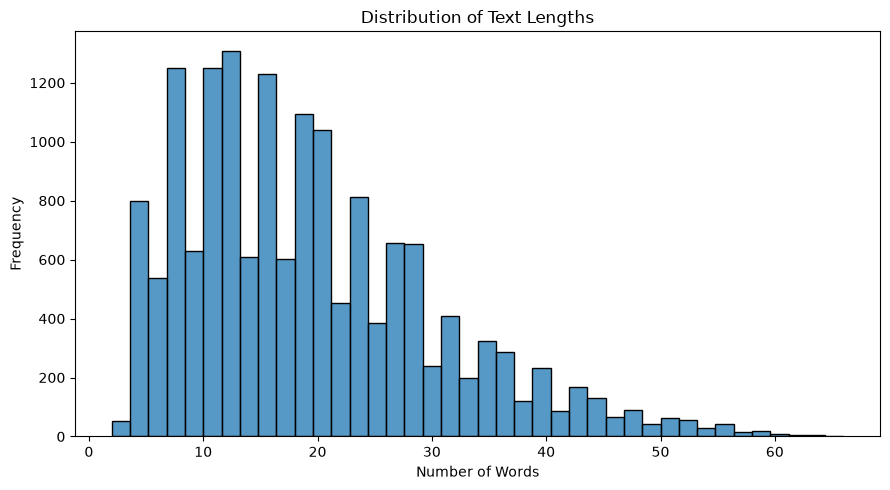

In [37]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=train_df,
    x="word_count",
    bins=40
)

plt.title("Distribution of Text Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

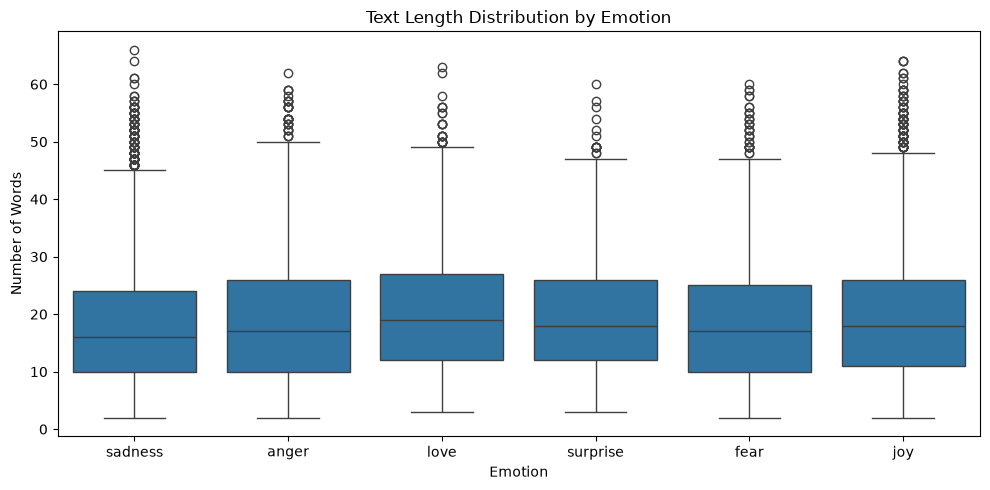

In [39]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=train_df,
    x="emotion",
    y="word_count"
)

plt.title("Text Length Distribution by Emotion")
plt.xlabel("Emotion")
plt.ylabel("Number of Words")

plt.tight_layout()
plt.show()

### Conclusions From the Plots and Statistics
1. There are some severely unrappresented categories like Surprise and Love ( 3.58% and 8.15% respectively )

2. There are 31 duplicated text ( I need to handle somehow )
4. No empty text, so apart from the duplicates everything else is valuable and it's going to be used for the training
5. Dataset distribution for the model: 80% Training, 10% Validation, 10% Test
6. 